# RICO - Component-Statistiken

Zaehlt fuer **alle 66.261 RICO-Screens**, wie viele GUI-Komponenten pro JSON enthalten
sind - einmal auf den **Rohdaten** (`../rico-data/data/layouts/<id>.json`) und einmal
auf den **gecleanten** JSONs (`utils.clean_screen()`, also die Repraesentation, die als
Encoder-Input und Rekonstruktions-Target dient).

Berichtet werden jeweils

* die **Gesamtzahl der Komponenten pro Screen** (mean, median, sd, IQR, Boxplot),
* die **Zahl je Komponententyp** (z. B. `Button`, `WebView`, `TextView`) pro Screen
  (mean, median, sd, IQR, Boxplot der haeufigsten Typen).

**Zaehl-Definition**

* *Roh*: jeder Knoten im Viewhierarchie-Baum unter `activity.root` - inklusive Wurzel
  (`DecorView`) und inklusive unsichtbarer bzw. inerter Layout-Container.
* *Clean*: jede Komponente im `components`-Wald von `utils.clean_screen()`, rekursiv
  ueber `children`. Unsichtbare / flaechenlose Knoten sind hier bereits verworfen und
  inertes Scaffolding (`DecorView`, die meisten `*Layout`, `ScrollView`, `ViewPager`)
  ist ausgepackt - *ausser* es ist `clickable`, dann bleibt es erhalten.
* Der **Typ** einer Komponente ist das letzte Segment des Klassenpfads,
  also `android.widget.Button` -> `Button`.

**Teil D** wertet zusaetzlich die Interaction Traces aus
(`../rico-data/data/traces/filtered_traces/`): Anzahl Traces, Apps, Traces je App
und Screens je Trace.

In [1]:
import os, sys, glob
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import orjson
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

sys.path.insert(0, os.path.abspath("."))
import utils

RICO_DIR  = "../rico-data/data/layouts"
CACHE_DIR = "rico_metrics_cache"          # gitignored, damit der Scan nur einmal laeuft
os.makedirs(CACHE_DIR, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

bigsize = (10, 7)                         # /2.54 = cm2inch  (wie in den anderen Notebooks)
plt.rcParams["figure.dpi"] = 110

TOP_K = 15                                # Komponententypen im Boxplot
N_WORKERS = 8                             # Threads fuer den Scan (orjson gibt das GIL frei)

paths = sorted(glob.glob(os.path.join(RICO_DIR, "*.json")),
               key=lambda p: int(os.path.splitext(os.path.basename(p))[0]))
print(f"{len(paths)} RICO-Screens gefunden in {RICO_DIR}")

66261 RICO-Screens gefunden in ../rico-data/data/layouts


## 1 - Zaehl-Funktionen

In [2]:
def _short(node):
    """Letztes Segment des Klassenpfads: 'android.widget.Button' -> 'Button'."""
    return (node.get("class") or "").split(".")[-1] or "<no-class>"


def count_raw(root):
    """Counter ueber alle Knoten des rohen Viewhierarchie-Baums (inkl. Wurzel)."""
    counts = Counter()
    if not isinstance(root, dict):
        return counts
    stack = [root]
    while stack:
        node = stack.pop()
        if not isinstance(node, dict):        # RICO enthaelt vereinzelt null-Kinder
            continue
        counts[_short(node)] += 1
        stack.extend(node.get("children") or [])
    return counts


def count_clean(components):
    """Counter ueber alle Komponenten des gecleanten Waldes, rekursiv."""
    counts = Counter()
    stack = list(components)
    while stack:
        node = stack.pop()
        counts[_short(node)] += 1
        stack.extend(node.get("children") or [])
    return counts

## 2 - Scan ueber das gesamte Dataset

Ein Durchlauf parst jedes JSON genau einmal und leitet daraus beide Zaehlungen ab.
Ergebnis sind zwei Tabellen, die in `rico_metrics_cache/` zwischengespeichert werden:

* `totals` - eine Zeile je Screen mit `raw` / `clean` Gesamtzahl,
* `long`   - eine Zeile je (Screen, Variante, Typ) mit Zaehlung ungleich null.

Laufzeit beim ersten Mal ca. 3 Minuten (8 Threads), danach kommt alles aus dem Cache.

In [3]:
TOTALS_CACHE = os.path.join(CACHE_DIR, "per_screen_totals.csv.gz")
LONG_CACHE   = os.path.join(CACHE_DIR, "per_class_long.csv.gz")

FORCE_RESCAN = False    # auf True setzen, wenn utils.clean_screen() geaendert wurde


def scan_one(path):
    """Ein Screen -> (screen_id, app, activity, Counter(roh), Counter(clean))."""
    screen_id = int(os.path.splitext(os.path.basename(path))[0])
    with open(path, "rb") as fh:
        raw = orjson.loads(fh.read())

    root = (raw.get("activity") or {}).get("root")
    raw_counts = count_raw(root)
    # identische Cleaning-Logik wie utils.clean_screen(), nur ohne zweites Parsen
    components = utils.clean_node(root, *utils.device_frame(root)) if root else []
    clean_counts = count_clean(components)

    app, activity = utils.parse_activity_name(raw)
    return screen_id, app, activity, raw_counts, clean_counts


def scan_dataset(paths):
    total_rows, long_rows = [], []
    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        results = pool.map(scan_one, paths)          # behaelt die Reihenfolge bei
        for screen_id, app, activity, raw_counts, clean_counts in tqdm(
                results, total=len(paths), desc="RICO scan"):
            total_rows.append((screen_id, app, activity,
                               sum(raw_counts.values()), len(raw_counts),
                               sum(clean_counts.values()), len(clean_counts)))
            for cls, n in raw_counts.items():
                long_rows.append((screen_id, "raw", cls, n))
            for cls, n in clean_counts.items():
                long_rows.append((screen_id, "clean", cls, n))

    totals = pd.DataFrame(total_rows, columns=[
        "screen_id", "app", "activity",
        "raw_total", "raw_distinct", "clean_total", "clean_distinct"]).set_index("screen_id")
    long = pd.DataFrame(long_rows, columns=["screen_id", "variant", "class", "count"])
    long["variant"] = long["variant"].astype("category")
    long["class"] = long["class"].astype("category")
    return totals, long


if not FORCE_RESCAN and os.path.exists(TOTALS_CACHE) and os.path.exists(LONG_CACHE):
    totals = pd.read_csv(TOTALS_CACHE).set_index("screen_id")
    long = pd.read_csv(LONG_CACHE, dtype={"variant": "category", "class": "category"})
    print("aus Cache geladen")
else:
    totals, long = scan_dataset(paths)
    totals.to_csv(TOTALS_CACHE)
    long.to_csv(LONG_CACHE, index=False)
    print("gescannt und gecached")

N_SCREENS = len(totals)
print(f"{N_SCREENS} Screens, {len(long):,} (Screen, Typ)-Paare")
totals.head()

aus Cache geladen
66261 Screens, 1,852,643 (Screen, Typ)-Paare


,app,activity,raw_total,raw_distinct,clean_total,clean_distinct
screen_id,,,,,,
0,com.brc.PeriodTrackerDiary,MainActivity,21,14,1,1
1,com.brc.PeriodTrackerDiary,MainActivity,21,14,8,7
2,se.perigee.android.seven,ActivitySettingsGoggleFit,35,18,10,8
3,se.perigee.android.seven,WorkoutSessionActivity,75,20,10,8
4,se.perigee.android.seven,WorkoutSessionCompleteActivity,70,20,29,10


## 3 - Kennzahlen- und Plot-Helfer

In [4]:
def describe(series, label=""):
    """mean / median / sd / IQR (+ Quartile, Extremwerte) einer Zaehlreihe."""
    s = pd.Series(series, dtype="float64")
    q25, q75 = s.quantile([0.25, 0.75])
    return pd.Series({
        "n":      int(s.size),
        "mean":   s.mean(),
        "median": s.median(),
        "sd":     s.std(ddof=1),
        "iqr":    q75 - q25,
        "q25":    q25,
        "q75":    q75,
        "min":    s.min(),
        "max":    s.max(),
        "sum":    s.sum(),
    }, name=label)


def class_matrix(long, variant, classes, n_screens=None):
    """Screens x Typ Matrix der Zaehlungen; fehlende Kombinationen werden zu 0.

    Die Zeilenzahl wird auf `n_screens` aufgefuellt, damit Screens ohne einen
    einzigen Treffer korrekt als 0 in Mittelwert / Median / IQR eingehen.
    """
    classes = list(classes)
    sub = long[(long["variant"] == variant) & (long["class"].isin(classes))]
    mat = (sub.pivot_table(index="screen_id", columns="class", values="count",
                           aggfunc="sum", fill_value=0, observed=True)
              .reindex(columns=classes, fill_value=0))
    if n_screens is not None and len(mat) < n_screens:
        missing = n_screens - len(mat)
        pad = pd.DataFrame(0, index=[-i - 1 for i in range(missing)], columns=mat.columns)
        mat = pd.concat([mat, pad])
    return mat.astype("int32")


def class_stats(long, variant, n_screens, top_k=None):
    """Kennzahlen je Komponententyp, ueber ALLE Screens (Abwesenheit zaehlt als 0)."""
    sub = long[long["variant"] == variant]
    g = sub.groupby("class", observed=True)["count"]

    total = g.sum()
    present = g.size()                                  # Screens, in denen der Typ vorkommt
    order = total.sort_values(ascending=False).index
    if top_k:
        order = order[:top_k]

    mat = class_matrix(long, variant, order, n_screens)
    out = pd.DataFrame([describe(mat[c], c) for c in order])
    out["total_occurrences"] = total.reindex(order).values
    out["screens_present"] = present.reindex(order).values
    out["screens_present_pct"] = 100 * out["screens_present"] / n_screens
    out["mean_when_present"] = out["total_occurrences"] / out["screens_present"]
    return out[["mean", "median", "sd", "iqr", "q25", "q75", "min", "max",
                "total_occurrences", "screens_present", "screens_present_pct",
                "mean_when_present"]]


def boxplot(data, labels, title, ylabel, log=False, figsize=bigsize, ax=None, rot=60):
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    ax.boxplot(data, tick_labels=labels, showfliers=True,
               flierprops=dict(marker=".", markersize=2, alpha=0.15,
                               markerfacecolor="tab:blue", markeredgecolor="none"),
               medianprops=dict(color="tab:red", linewidth=1.6),
               boxprops=dict(color="0.3"), whiskerprops=dict(color="0.3"),
               capprops=dict(color="0.3"))
    if log:
        ax.set_yscale("symlog")
    ax.set_title(title, fontsize=10)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", labelrotation=rot)
    if rot:
        for lbl in ax.get_xticklabels():
            lbl.set_horizontalalignment("right")
    plt.tight_layout()
    return ax

---
# Teil A - Rohdaten

Alle Knoten der ungefilterten RICO-Viewhierarchie.

## A.1 - Komponenten pro Screen (gesamt)

In [5]:
pd.DataFrame([
    describe(totals["raw_total"], "raw: Komponenten je Screen"),
    describe(totals["raw_distinct"], "raw: versch. Typen je Screen"),
]).round(3)

,n,mean,median,sd,iqr,q25,q75,min,max,sum
raw: Komponenten je Screen,66261.0,96.156,65.0,93.745,103.0,30.0,133.0,2.0,2303.0,6371389.0
raw: versch. Typen je Screen,66261.0,20.061,18.0,9.942,13.0,13.0,26.0,2.0,165.0,1329293.0


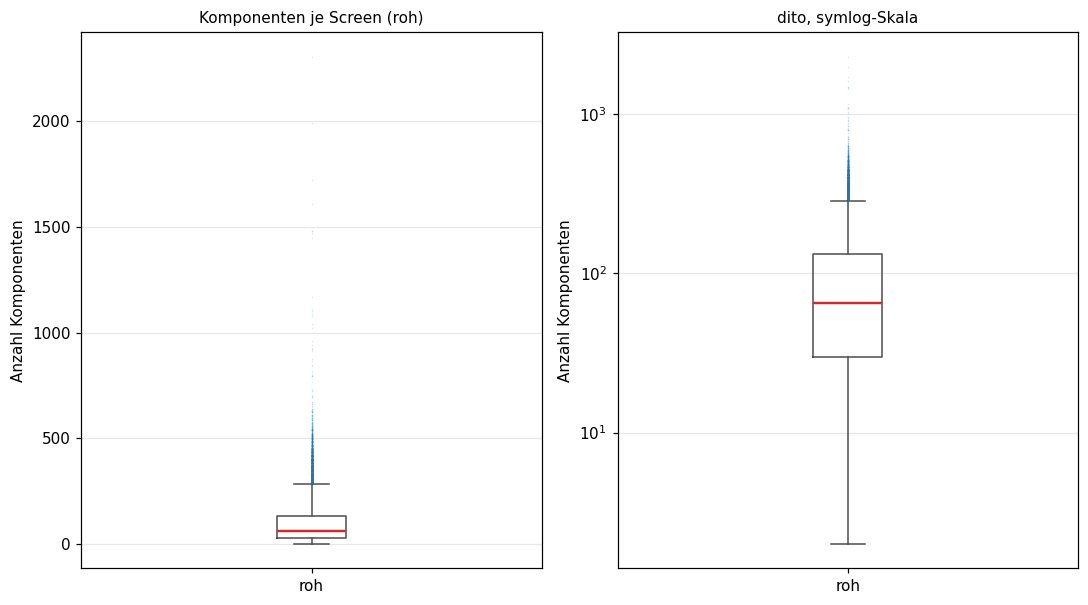

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(bigsize[0], bigsize[1] * 0.8))
boxplot([totals["raw_total"].values], ["roh"],
        "Komponenten je Screen (roh)", "Anzahl Komponenten", ax=axes[0], rot=0)
boxplot([totals["raw_total"].values], ["roh"],
        "dito, symlog-Skala", "Anzahl Komponenten", log=True, ax=axes[1], rot=0)
plt.tight_layout()
plt.show()

## A.2 - Komponenten je Typ (roh)

In [7]:
raw_class_stats = class_stats(long, "raw", N_SCREENS, top_k=40)
n_cls = long.loc[long["variant"] == "raw", "class"].nunique()
print(f"insgesamt {n_cls} verschiedene Klassen (roh)")
raw_class_stats.round(3)

insgesamt 25482 verschiedene Klassen (roh)


,mean,median,sd,iqr,q25,q75,min,max,total_occurrences,screens_present,screens_present_pct,mean_when_present
LinearLayout,16.002,9.0,20.495,18.0,3.0,21.0,0.0,580.0,1060314,65187,98.379,16.266
AppCompatTextView,9.033,0.0,19.499,9.0,0.0,9.0,0.0,518.0,598563,26342,39.755,22.723
RelativeLayout,7.757,3.0,12.369,9.0,1.0,10.0,0.0,393.0,513956,50630,76.410,10.151
TextView,7.654,1.0,17.934,7.0,0.0,7.0,0.0,806.0,507170,39872,60.174,12.720
ImageView,6.667,1.0,14.181,7.0,0.0,7.0,0.0,433.0,441755,34263,51.709,12.893
FrameLayout,5.981,3.0,8.460,6.0,1.0,7.0,0.0,214.0,396277,65271,98.506,6.071
AppCompatImageView,5.584,0.0,13.393,4.0,0.0,4.0,0.0,1022.0,369996,23151,34.939,15.982
View,4.922,2.0,8.395,6.0,0.0,6.0,0.0,406.0,326148,48102,72.595,6.780
ViewStub,1.294,1.0,2.274,0.0,1.0,1.0,0.0,167.0,85770,57704,87.086,1.486
PhoneWindow$DecorView,1.008,1.0,0.320,0.0,1.0,1.0,0.0,15.0,66812,65247,98.470,1.024


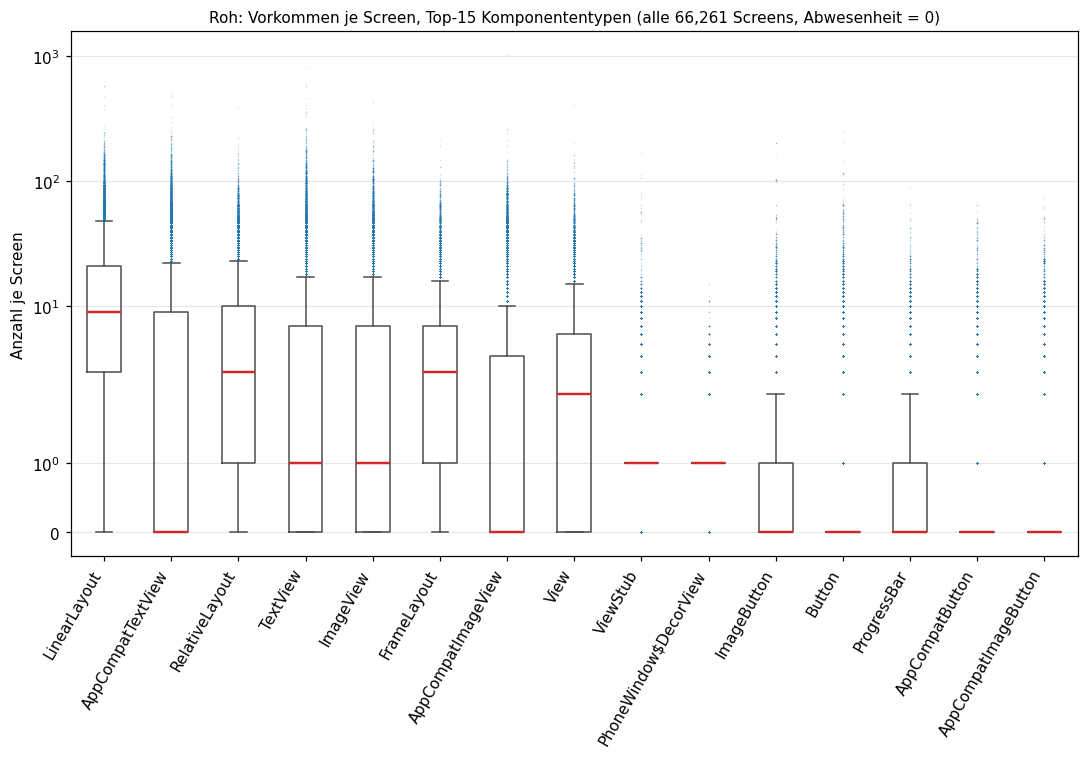

In [8]:
raw_top = list(raw_class_stats.index[:TOP_K])
raw_mat = class_matrix(long, "raw", raw_top, N_SCREENS)

boxplot([raw_mat[c].values for c in raw_top], raw_top,
        f"Roh: Vorkommen je Screen, Top-{TOP_K} Komponententypen "
        f"(alle {N_SCREENS:,} Screens, Abwesenheit = 0)",
        "Anzahl je Screen", log=True)
plt.show()

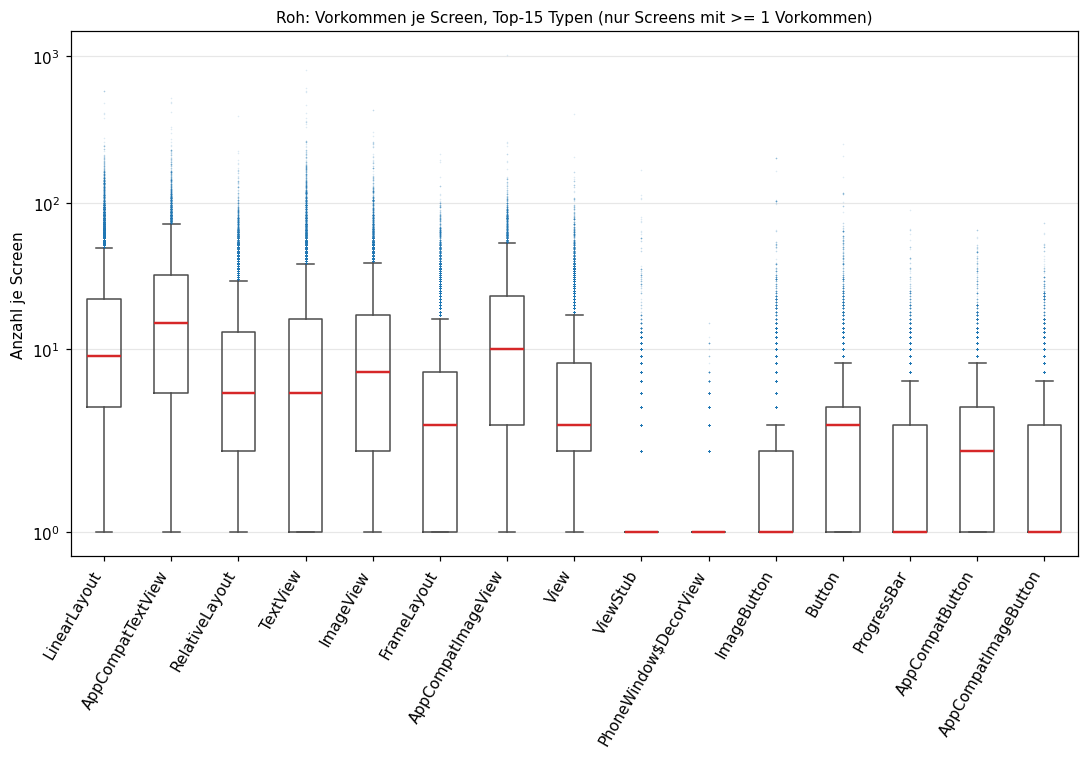

In [9]:
# Variante: nur Screens, in denen der Typ ueberhaupt vorkommt
boxplot([raw_mat[c][raw_mat[c] > 0].values for c in raw_top], raw_top,
        f"Roh: Vorkommen je Screen, Top-{TOP_K} Typen (nur Screens mit >= 1 Vorkommen)",
        "Anzahl je Screen", log=True)
plt.show()

## A.3 - Ausgewaehlte Widget-Typen

Die Top-Liste wird von Layout-Containern dominiert; hier explizit die klassischen
interaktiven Widgets.

In [10]:
WIDGETS = ["Button", "ImageButton", "TextView", "EditText", "ImageView", "CheckBox",
           "RadioButton", "Switch", "ToggleButton", "SeekBar", "ProgressBar", "Spinner",
           "WebView", "ListView", "RecyclerView", "GridView", "CardView", "Toolbar",
           "AppCompatButton", "AppCompatTextView", "AppCompatImageView", "AppCompatEditText"]

raw_widget_stats = class_stats(long, "raw", N_SCREENS).reindex(WIDGETS).dropna(how="all")
raw_widget_stats.round(3)

,mean,median,sd,iqr,q25,q75,min,max,total_occurrences,screens_present,screens_present_pct,mean_when_present
Button,0.898,0.0,3.769,0.0,0.0,0.0,0.0,253.0,59479,13893,20.967,4.281
ImageButton,0.915,0.0,3.390,1.0,0.0,1.0,0.0,201.0,60603,22137,33.409,2.738
TextView,7.654,1.0,17.934,7.0,0.0,7.0,0.0,806.0,507170,39872,60.174,12.720
EditText,0.145,0.0,1.262,0.0,0.0,0.0,0.0,92.0,9636,4142,6.251,2.326
ImageView,6.667,1.0,14.181,7.0,0.0,7.0,0.0,433.0,441755,34263,51.709,12.893
CheckBox,0.137,0.0,1.143,0.0,0.0,0.0,0.0,62.0,9099,2533,3.823,3.592
RadioButton,0.083,0.0,0.809,0.0,0.0,0.0,0.0,49.0,5500,1202,1.814,4.576
Switch,0.034,0.0,0.412,0.0,0.0,0.0,0.0,16.0,2281,874,1.319,2.610
ToggleButton,0.072,0.0,0.968,0.0,0.0,0.0,0.0,65.0,4745,1356,2.046,3.499
SeekBar,0.035,0.0,0.380,0.0,0.0,0.0,0.0,34.0,2312,1411,2.129,1.639


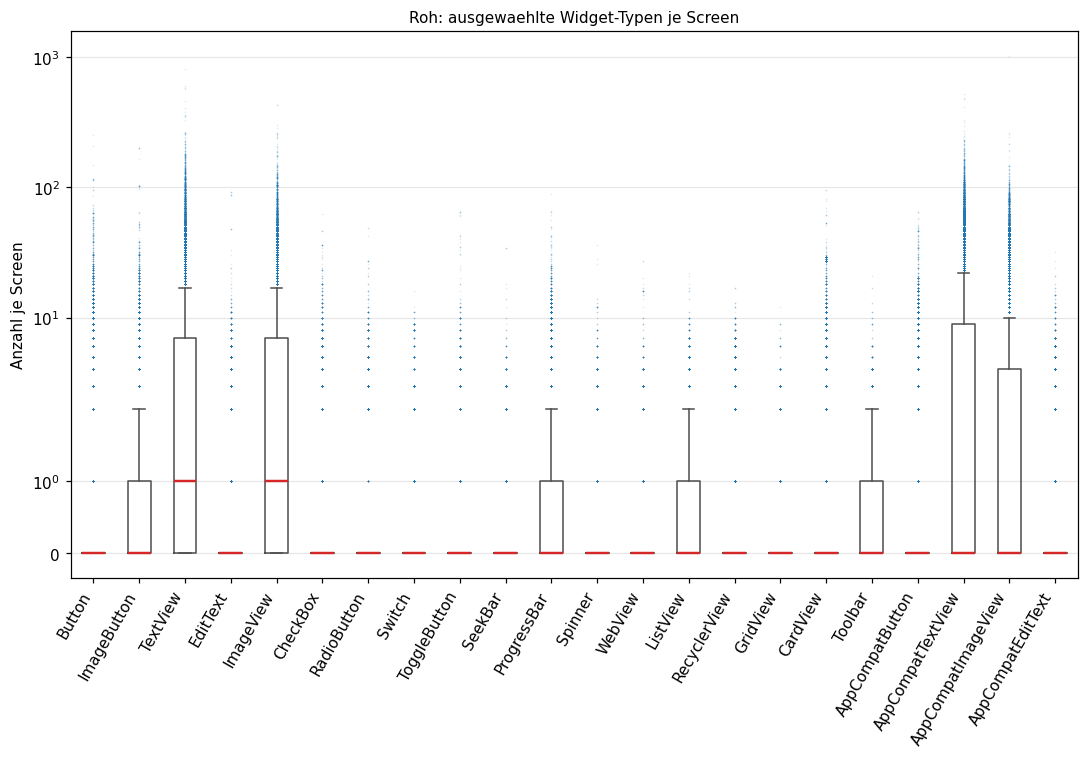

In [11]:
wid = list(raw_widget_stats.index)
raw_wmat = class_matrix(long, "raw", wid, N_SCREENS)
boxplot([raw_wmat[c].values for c in wid], wid,
        "Roh: ausgewaehlte Widget-Typen je Screen", "Anzahl je Screen", log=True)
plt.show()

---
# Teil B - Gecleante JSONs

Dieselben Auswertungen auf `utils.clean_screen()`-Output, also der Repraesentation,
die tatsaechlich embeddet bzw. rekonstruiert wird.

## B.1 - Komponenten pro Screen (gesamt)

In [12]:
pd.DataFrame([
    describe(totals["clean_total"], "clean: Komponenten je Screen"),
    describe(totals["clean_distinct"], "clean: versch. Typen je Screen"),
]).round(3)

,n,mean,median,sd,iqr,q25,q75,min,max,sum
clean: Komponenten je Screen,66261.0,22.921,17.0,19.880,23.0,9.0,32.0,0.0,472.0,1518766.0
clean: versch. Typen je Screen,66261.0,7.898,7.0,4.511,7.0,4.0,11.0,0.0,44.0,523350.0


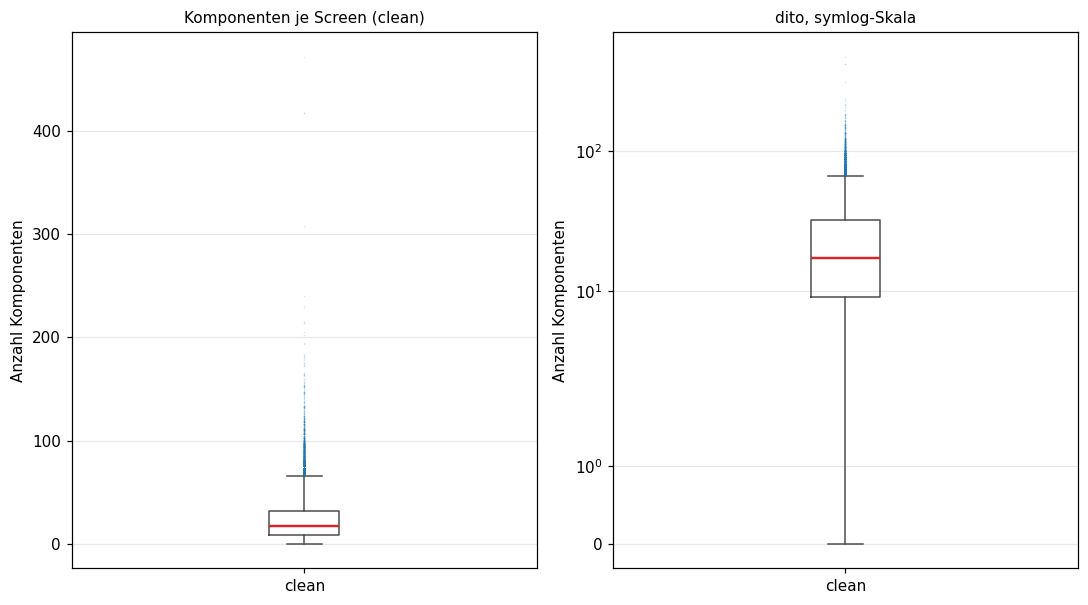

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(bigsize[0], bigsize[1] * 0.8))
boxplot([totals["clean_total"].values], ["clean"],
        "Komponenten je Screen (clean)", "Anzahl Komponenten", ax=axes[0], rot=0)
boxplot([totals["clean_total"].values], ["clean"],
        "dito, symlog-Skala", "Anzahl Komponenten", log=True, ax=axes[1], rot=0)
plt.tight_layout()
plt.show()

In [14]:
empty = int((totals["clean_total"] == 0).sum())
print(f"leere Screens nach dem Cleaning: {empty} ({100 * empty / N_SCREENS:.2f} %)")

leere Screens nach dem Cleaning: 169 (0.26 %)


## B.2 - Komponenten je Typ (clean)

In [15]:
clean_class_stats = class_stats(long, "clean", N_SCREENS, top_k=40)
n_cls = long.loc[long["variant"] == "clean", "class"].nunique()
print(f"insgesamt {n_cls} verschiedene Klassen (clean)")
clean_class_stats.round(3)

insgesamt 18032 verschiedene Klassen (clean)


,mean,median,sd,iqr,q25,q75,min,max,total_occurrences,screens_present,screens_present_pct,mean_when_present
AppCompatTextView,3.173,0.0,6.966,3.0,0.0,3.0,0.0,199.0,210220,23850,35.994,8.814
TextView,3.112,0.0,6.775,3.0,0.0,3.0,0.0,382.0,206195,33058,49.891,6.237
ImageView,2.343,0.0,5.110,2.0,0.0,2.0,0.0,218.0,155224,29364,44.316,5.286
AppCompatImageView,1.673,0.0,3.985,1.0,0.0,1.0,0.0,57.0,110854,19468,29.381,5.694
LinearLayout,0.929,0.0,2.324,1.0,0.0,1.0,0.0,65.0,61535,20193,30.475,3.047
RelativeLayout,0.606,0.0,2.033,0.0,0.0,0.0,0.0,60.0,40155,11864,17.905,3.385
ImageButton,0.482,0.0,1.281,1.0,0.0,1.0,0.0,48.0,31916,19348,29.200,1.650
Button,0.387,0.0,1.646,0.0,0.0,0.0,0.0,101.0,25645,9546,14.407,2.686
Toolbar,0.374,0.0,0.498,1.0,0.0,1.0,0.0,6.0,24805,24427,36.865,1.015
ActionMenuItemView,0.303,0.0,0.695,0.0,0.0,0.0,0.0,9.0,20052,13523,20.409,1.483


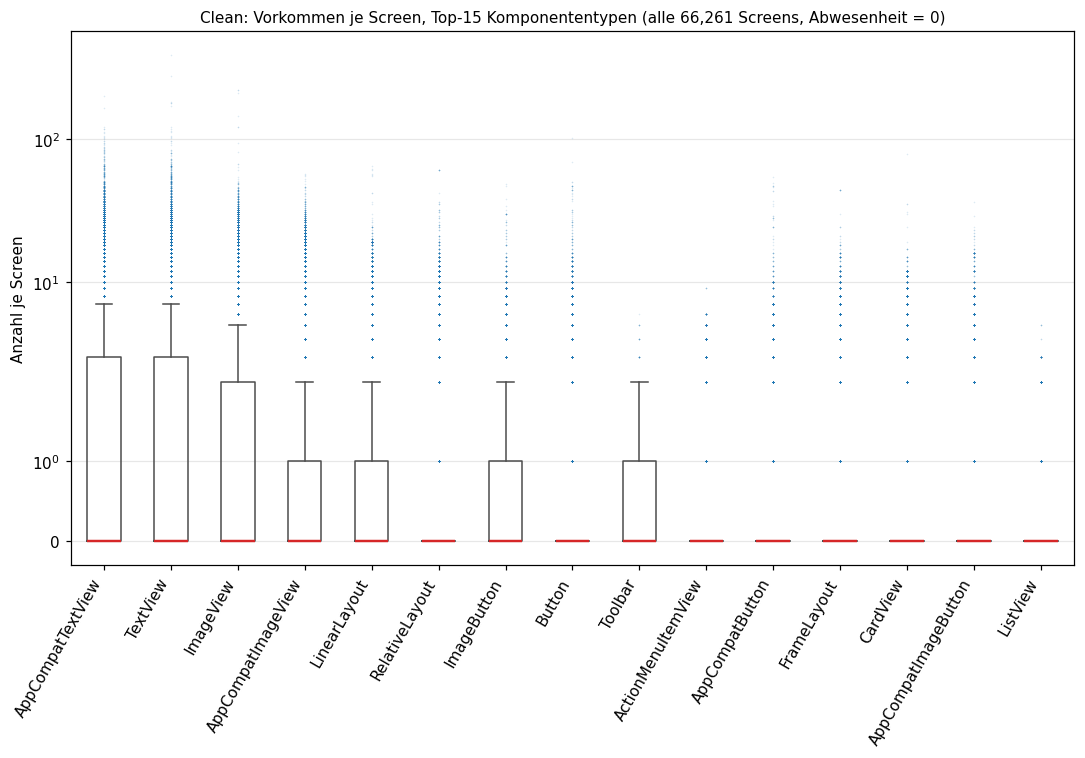

In [16]:
clean_top = list(clean_class_stats.index[:TOP_K])
clean_mat = class_matrix(long, "clean", clean_top, N_SCREENS)

boxplot([clean_mat[c].values for c in clean_top], clean_top,
        f"Clean: Vorkommen je Screen, Top-{TOP_K} Komponententypen "
        f"(alle {N_SCREENS:,} Screens, Abwesenheit = 0)",
        "Anzahl je Screen", log=True)
plt.show()

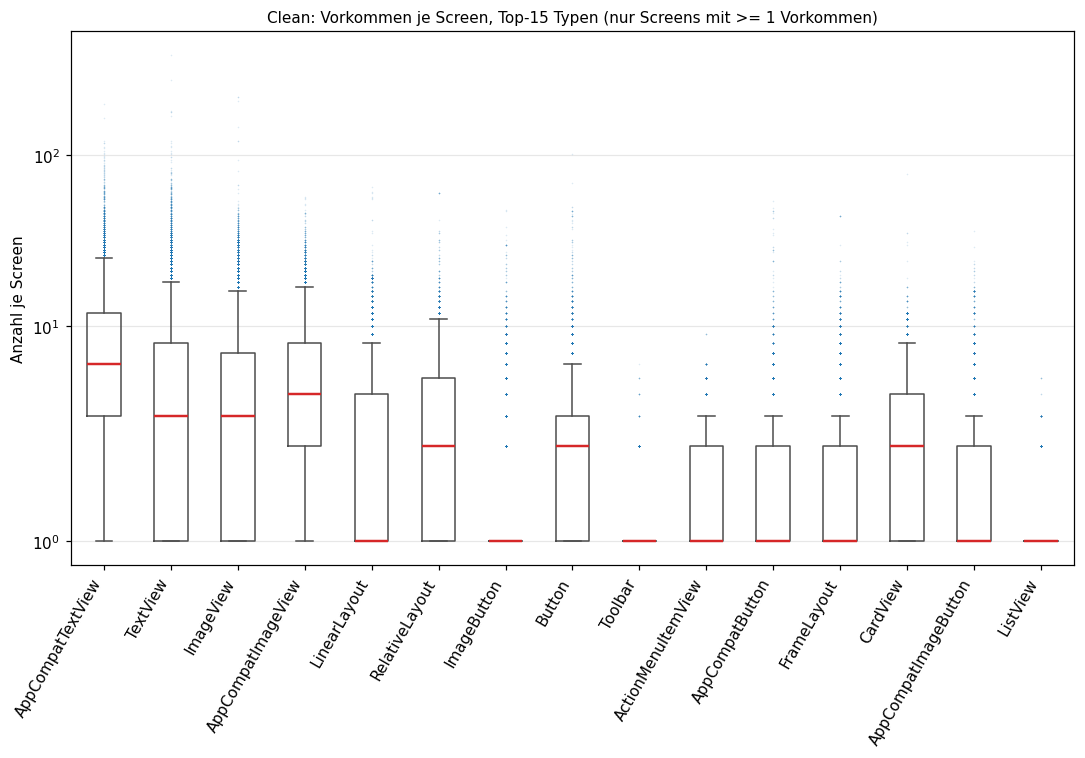

In [17]:
boxplot([clean_mat[c][clean_mat[c] > 0].values for c in clean_top], clean_top,
        f"Clean: Vorkommen je Screen, Top-{TOP_K} Typen (nur Screens mit >= 1 Vorkommen)",
        "Anzahl je Screen", log=True)
plt.show()

## B.3 - Ausgewaehlte Widget-Typen

In [18]:
clean_widget_stats = class_stats(long, "clean", N_SCREENS).reindex(WIDGETS).dropna(how="all")
clean_widget_stats.round(3)

,mean,median,sd,iqr,q25,q75,min,max,total_occurrences,screens_present,screens_present_pct,mean_when_present
Button,0.387,0.0,1.646,0.0,0.0,0.0,0.0,101.0,25645,9546,14.407,2.686
ImageButton,0.482,0.0,1.281,1.0,0.0,1.0,0.0,48.0,31916,19348,29.200,1.650
TextView,3.112,0.0,6.775,3.0,0.0,3.0,0.0,382.0,206195,33058,49.891,6.237
EditText,0.070,0.0,0.482,0.0,0.0,0.0,0.0,30.0,4621,2451,3.699,1.885
ImageView,2.343,0.0,5.110,2.0,0.0,2.0,0.0,218.0,155224,29364,44.316,5.286
CheckBox,0.070,0.0,0.598,0.0,0.0,0.0,0.0,26.0,4608,1721,2.597,2.678
RadioButton,0.041,0.0,0.460,0.0,0.0,0.0,0.0,19.0,2729,708,1.069,3.855
Switch,0.015,0.0,0.236,0.0,0.0,0.0,0.0,11.0,1017,483,0.729,2.106
ToggleButton,0.036,0.0,0.418,0.0,0.0,0.0,0.0,21.0,2403,861,1.299,2.791
SeekBar,0.016,0.0,0.195,0.0,0.0,0.0,0.0,13.0,1093,757,1.142,1.444


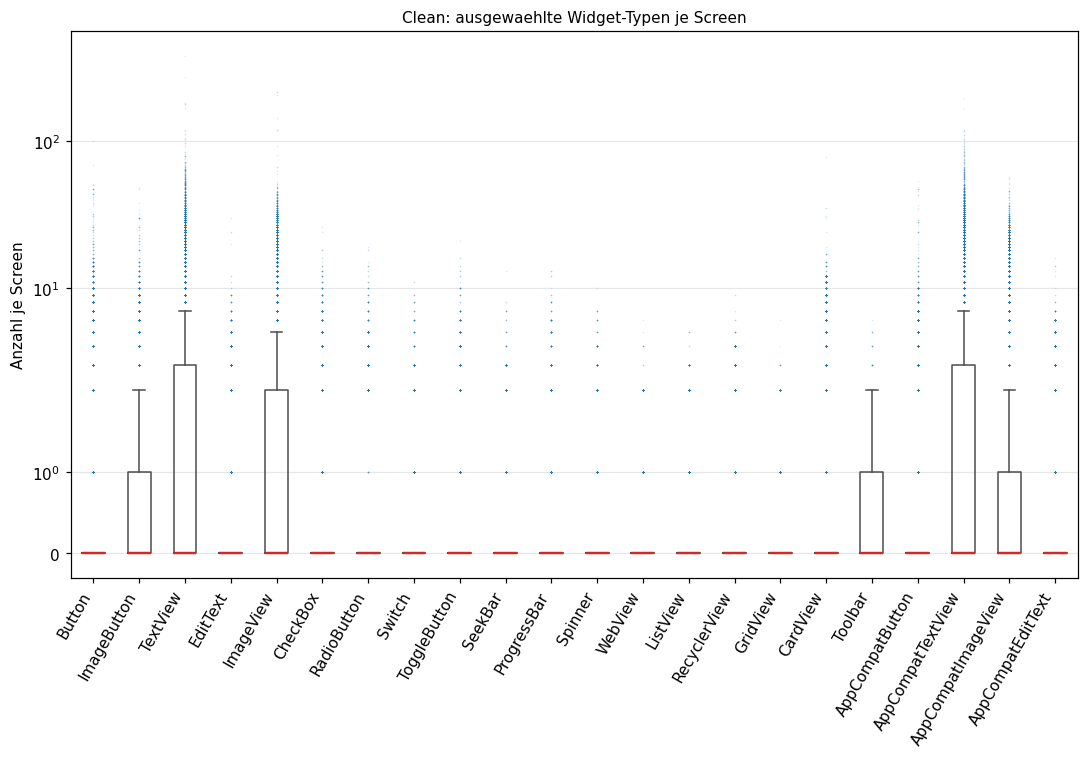

In [19]:
cwid = list(clean_widget_stats.index)
clean_wmat = class_matrix(long, "clean", cwid, N_SCREENS)
boxplot([clean_wmat[c].values for c in cwid], cwid,
        "Clean: ausgewaehlte Widget-Typen je Screen", "Anzahl je Screen", log=True)
plt.show()

---
# Teil C - Vergleich roh vs. clean

In [20]:
cmp = pd.DataFrame([
    describe(totals["raw_total"], "roh"),
    describe(totals["clean_total"], "clean"),
])
cmp["reduktion_%"] = [np.nan, 100 * (1 - cmp.loc["clean", "sum"] / cmp.loc["roh", "sum"])]
cmp.round(3)

,n,mean,median,sd,iqr,q25,q75,min,max,sum,reduktion_%
roh,66261.0,96.156,65.0,93.745,103.0,30.0,133.0,2.0,2303.0,6371389.0,NaN
clean,66261.0,22.921,17.0,19.880,23.0,9.0,32.0,0.0,472.0,1518766.0,76.163


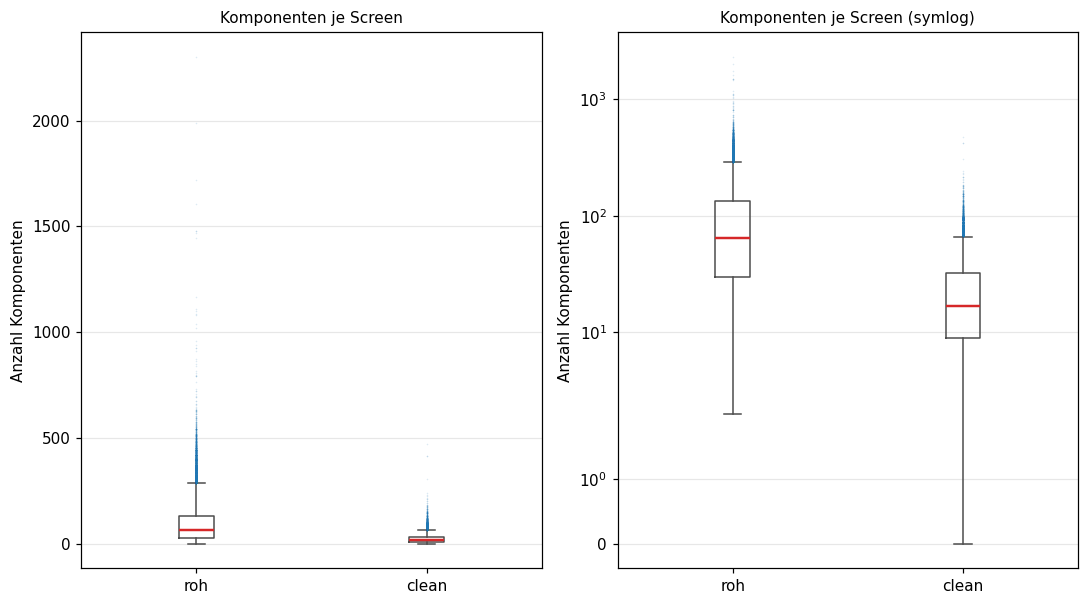

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(bigsize[0], bigsize[1] * 0.8))
boxplot([totals["raw_total"].values, totals["clean_total"].values], ["roh", "clean"],
        "Komponenten je Screen", "Anzahl Komponenten", ax=axes[0], rot=0)
boxplot([totals["raw_total"].values, totals["clean_total"].values], ["roh", "clean"],
        "Komponenten je Screen (symlog)", "Anzahl Komponenten", log=True, ax=axes[1], rot=0)
plt.tight_layout()
plt.show()

n           66261.000
mean           29.636
median         28.169
sd             15.192
iqr            22.200
q25            17.544
q75            39.744
min             0.000
max           100.000
sum       1963678.886
Name: erhaltene Komponenten je Screen [%], dtype: float64


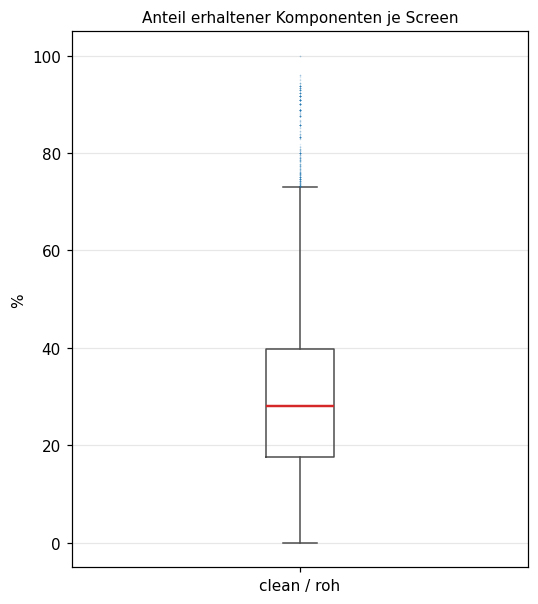

In [22]:
# Erhaltungsquote je Screen
keep = (totals["clean_total"] / totals["raw_total"].replace(0, np.nan)).dropna()
print(describe(100 * keep, "erhaltene Komponenten je Screen [%]").round(3))

_, ax = plt.subplots(figsize=(bigsize[0] * 0.5, bigsize[1] * 0.8))
boxplot([100 * keep.values], ["clean / roh"],
        "Anteil erhaltener Komponenten je Screen", "%", ax=ax, rot=0)
plt.show()

---
# Teil D - Interaction Traces

Quelle: `../rico-data/data/traces/filtered_traces/<app>/<trace>/`.
Die Screens eines Traces liegen in `view_hierarchies/<key>.json`, die zugehoerigen
Gesten in `gestures.json`.

Zwei Fallstricke:

* Das Verzeichnis enthaelt macOS-AppleDouble-Dateien (`._221.json`) neben den echten
  (`221.json`). Sie werden hier verworfen - ungefiltert wuerde jede Trace-Laenge
  verdoppelt. Nach dem Filtern stimmen `view_hierarchies/` und die Schluessel in
  `gestures.json` exakt ueberein (geprueft in D.1).
* Die Trace-Schluessel sind **pro Trace** vergeben und keine globalen Layout-Ids
  (siehe `trace_index.py`). Fuer den Bezug zu den Embeddings zaehlt daher zusaetzlich,
  wie viele Screens eines Traces ueber `trace_layout_index.csv` aufgeloest werden
  koennen - das ist die tatsaechlich nutzbare Trace-Laenge (D.4).

## D.1 - Traces einlesen

In [23]:
TRACES_DIR   = "../rico-data/data/traces/filtered_traces"
TRACE_INDEX  = "trace_layout_index.csv"
TRACES_CACHE = os.path.join(CACHE_DIR, "per_trace.csv.gz")


def scan_trace(app_trace):
    """(app, trace) -> Screens laut view_hierarchies/ und laut gestures.json."""
    app, trace = app_trace
    tdir = os.path.join(TRACES_DIR, app, trace)

    vh_dir = os.path.join(tdir, "view_hierarchies")
    screens = []
    if os.path.isdir(vh_dir):
        # ._<name>.json sind macOS-Resource-Forks, keine Screens
        screens = [os.path.splitext(f)[0] for f in os.listdir(vh_dir)
                   if f.endswith(".json") and not f.startswith("._")]

    gpath = os.path.join(tdir, "gestures.json")
    n_gestures = np.nan
    if os.path.exists(gpath):
        with open(gpath, "rb") as fh:
            n_gestures = len(orjson.loads(fh.read()))

    return app, trace, len(screens), n_gestures


def scan_traces():
    app_traces = []
    for app in sorted(os.listdir(TRACES_DIR)):
        adir = os.path.join(TRACES_DIR, app)
        if not os.path.isdir(adir):
            continue
        for trace in sorted(os.listdir(adir)):
            if os.path.isdir(os.path.join(adir, trace)):
                app_traces.append((app, trace))

    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        rows = list(tqdm(pool.map(scan_trace, app_traces),
                         total=len(app_traces), desc="Trace scan"))
    return pd.DataFrame(rows, columns=["app", "trace", "n_screens", "n_gestures"])


if not FORCE_RESCAN and os.path.exists(TRACES_CACHE):
    traces = pd.read_csv(TRACES_CACHE)
    print("aus Cache geladen")
else:
    traces = scan_traces()
    traces.to_csv(TRACES_CACHE, index=False)
    print("gescannt und gecached")

assert (traces["n_screens"] == traces["n_gestures"]).all(), \
    "view_hierarchies/ und gestures.json stimmen nicht ueberein"
print("view_hierarchies/ deckt sich fuer jeden Trace mit gestures.json")
traces.head()

aus Cache geladen
view_hierarchies/ deckt sich fuer jeden Trace mit gestures.json


,app,trace,n_screens,n_gestures
0,B4A.BigFivePersonalityTest,trace_0,1,1
1,CN.MyPrivateMessages,trace_0,1,1
2,DOCECG2.doctor,trace_0,1,1
3,Gecko.Droid.PhysicsHelper,trace_0,2,2
4,Gecko.Droid.PhysicsHelper,trace_2,3,3


## D.2 - Traces, Apps, Traces je App

In [24]:
n_traces = len(traces)
n_apps = traces["app"].nunique()
n_trace_screens = int(traces["n_screens"].sum())

print(f"Traces gesamt        : {n_traces:,}")
print(f"eindeutige Apps      : {n_apps:,}")
print(f"Screens in Traces    : {n_trace_screens:,}")
print(f"Screens im Layouts-Korpus: {N_SCREENS:,}"
      f"  -> {'identisch' if n_trace_screens == N_SCREENS else 'abweichend'}")
print(f"Traces je App        : {n_traces / n_apps:.3f} (Mittel)")

Traces gesamt        : 10,292
eindeutige Apps      : 9,384
Screens in Traces    : 66,261
Screens im Layouts-Korpus: 66,261  -> identisch
Traces je App        : 1.097 (Mittel)


In [25]:
traces_per_app = traces.groupby("app").size().rename("n_traces")
tpa_stats = describe(traces_per_app, "Traces je App")
print(tpa_stats.round(3))

print("\nVerteilung:")
dist = traces_per_app.value_counts().sort_index().rename("Apps").to_frame()
dist.index.name = "Traces je App"
dist["Anteil %"] = (100 * dist["Apps"] / n_apps).round(2)
dist

n          9384.000
mean          1.097
median        1.000
sd            0.353
iqr           0.000
q25           1.000
q75           1.000
min           1.000
max           4.000
sum       10292.000
Name: Traces je App, dtype: float64

Verteilung:


,Apps,Anteil %
Traces je App,,
1,8647,92.15
2,570,6.07
3,163,1.74
4,4,0.04


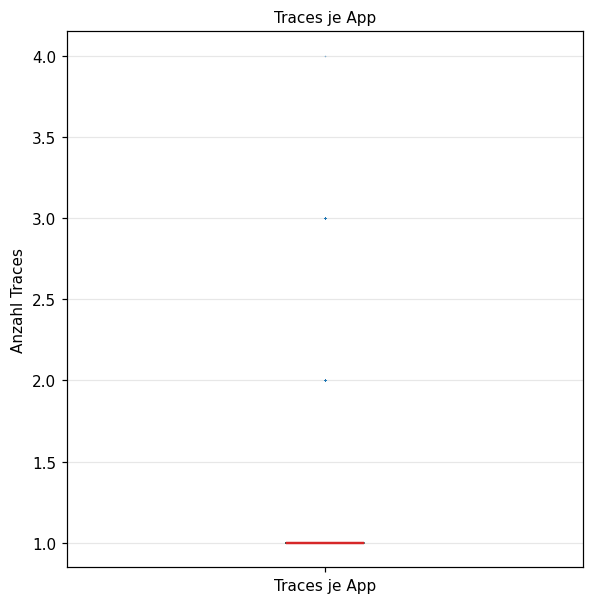

In [26]:
_, ax = plt.subplots(figsize=(bigsize[0] * 0.55, bigsize[1] * 0.8))
boxplot([traces_per_app.values], ["Traces je App"],
        "Traces je App", "Anzahl Traces", ax=ax, rot=0)
plt.show()

## D.3 - Screens je Trace

In [27]:
screens_per_trace_stats = describe(traces["n_screens"], "Screens je Trace")
screens_per_app_stats = describe(traces.groupby("app")["n_screens"].sum(), "Screens je App")
pd.DataFrame([screens_per_trace_stats, screens_per_app_stats]).round(3)

,n,mean,median,sd,iqr,q25,q75,min,max,sum
Screens je Trace,10292.0,6.438,4.0,6.179,7.0,2.0,9.0,1.0,53.0,66261.0
Screens je App,9384.0,7.061,5.0,7.146,7.0,2.0,9.0,1.0,76.0,66261.0


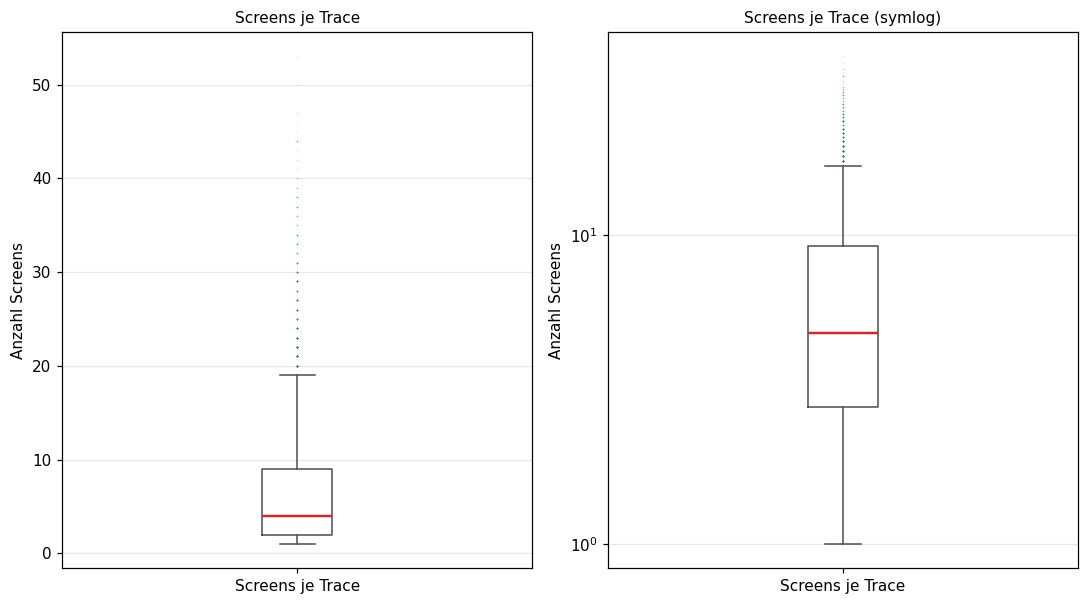

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(bigsize[0], bigsize[1] * 0.8))
boxplot([traces["n_screens"].values], ["Screens je Trace"],
        "Screens je Trace", "Anzahl Screens", ax=axes[0], rot=0)
boxplot([traces["n_screens"].values], ["Screens je Trace"],
        "Screens je Trace (symlog)", "Anzahl Screens", log=True, ax=axes[1], rot=0)
plt.tight_layout()
plt.show()

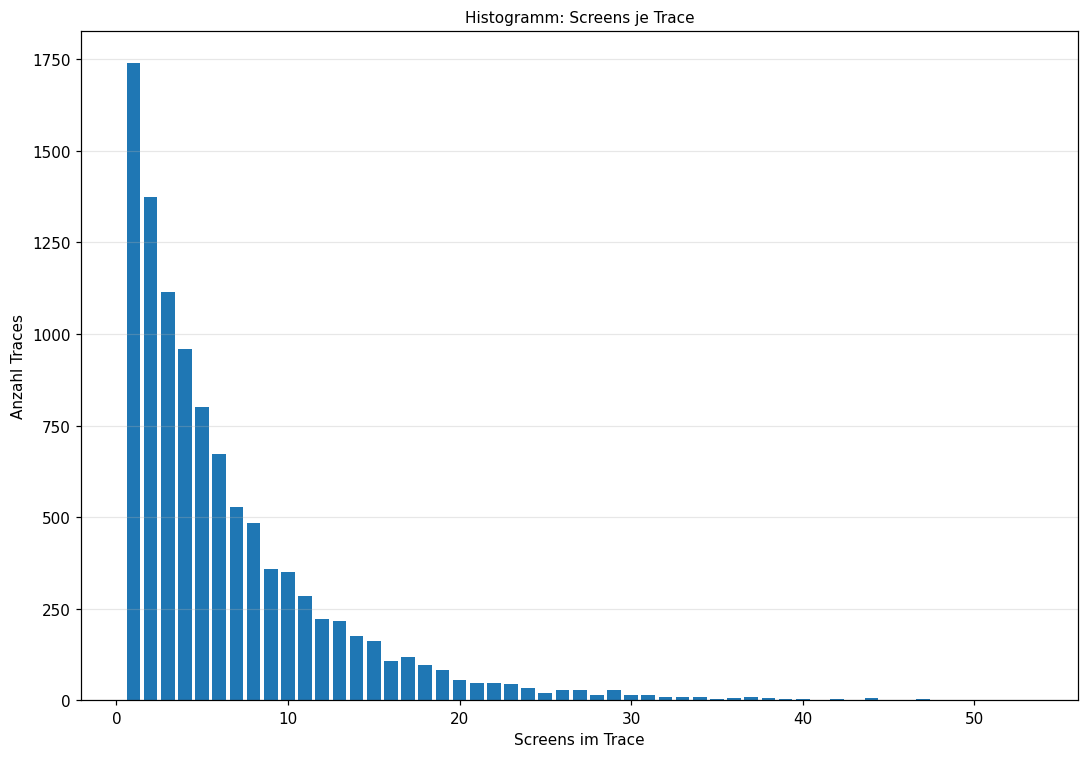

Traces mit >=  2 Screens:  8,552 (83.09 %)
Traces mit >=  3 Screens:  7,179 (69.75 %)
Traces mit >=  4 Screens:  6,063 (58.91 %)
Traces mit >=  5 Screens:  5,104 (49.59 %)
Traces mit >= 11 Screens:  1,910 (18.56 %)


In [29]:
_, ax = plt.subplots(figsize=bigsize)
counts = traces["n_screens"].value_counts().sort_index()
ax.bar(counts.index, counts.values, color="tab:blue", edgecolor="none")
ax.set_title("Histogramm: Screens je Trace", fontsize=10)
ax.set_xlabel("Screens im Trace")
ax.set_ylabel("Anzahl Traces")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Wie viele Traces sind fuer die Sequenzaufgabe ueberhaupt lang genug?
for k in (2, 3, 4, 5, 11):
    n = int((traces["n_screens"] >= k).sum())
    print(f"Traces mit >= {k:2d} Screens: {n:6,} ({100 * n / n_traces:5.2f} %)")

## D.4 - Nutzbare Trace-Laenge (Join auf die Layouts-Ids)

`trace_layout_index.csv` ordnet jedem Trace-Screen die globale Layout-Id zu, unter der
das Embedding liegt. Screens ohne Match sind verworfen, d. h. fuer die
Sequenz-Experimente ist die *nutzbare* Trace-Laenge relevant, nicht die auf der Platte.

Screens auf der Platte : 66,261
davon aufgeloest       : 66,157 (99.84 %)
Traces mit Verlust     : 91
Traces ohne jeden Match: 16
Match-Methoden         : {'full_doc_hash': np.int64(66154), 'root_hash': np.int64(3)}


,n,mean,median,sd,iqr,q25,q75,min,max,sum
Screens je Trace (Platte),10292.0,6.438,4.0,6.179,7.0,2.0,9.0,1.0,53.0,66261.0
Screens je Trace (aufgeloest),10292.0,6.428,4.0,6.183,7.0,2.0,9.0,0.0,53.0,66157.0


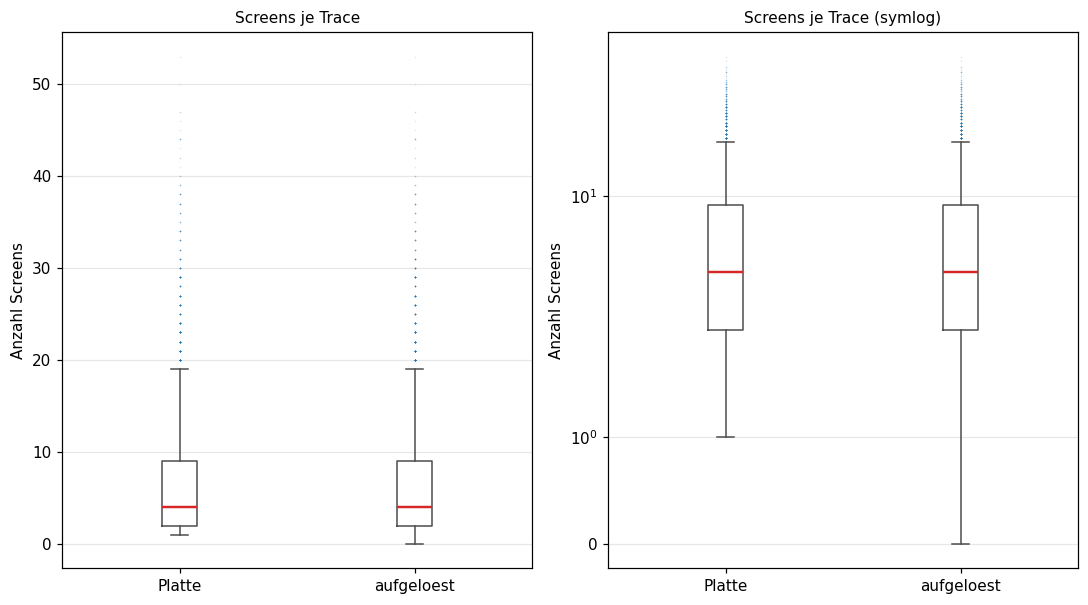

In [30]:
if os.path.exists(TRACE_INDEX):
    tidx = pd.read_csv(TRACE_INDEX)
    matched = tidx.groupby(["app", "trace"]).size().rename("n_matched")

    tr = traces.set_index(["app", "trace"]).join(matched).fillna({"n_matched": 0})
    tr["n_matched"] = tr["n_matched"].astype(int)
    tr["lost"] = tr["n_screens"] - tr["n_matched"]

    print(f"Screens auf der Platte : {int(tr['n_screens'].sum()):,}")
    print(f"davon aufgeloest       : {int(tr['n_matched'].sum()):,} "
          f"({100 * tr['n_matched'].sum() / tr['n_screens'].sum():.2f} %)")
    print(f"Traces mit Verlust     : {int((tr['lost'] > 0).sum()):,}")
    print(f"Traces ohne jeden Match: {int((tr['n_matched'] == 0).sum()):,}")
    print(f"Match-Methoden         : {dict(tidx['match_method'].value_counts())}")

    display(pd.DataFrame([
        describe(tr["n_screens"], "Screens je Trace (Platte)"),
        describe(tr["n_matched"], "Screens je Trace (aufgeloest)"),
    ]).round(3))

    fig, axes = plt.subplots(1, 2, figsize=(bigsize[0], bigsize[1] * 0.8))
    boxplot([tr["n_screens"].values, tr["n_matched"].values], ["Platte", "aufgeloest"],
            "Screens je Trace", "Anzahl Screens", ax=axes[0], rot=0)
    boxplot([tr["n_screens"].values, tr["n_matched"].values], ["Platte", "aufgeloest"],
            "Screens je Trace (symlog)", "Anzahl Screens", log=True, ax=axes[1], rot=0)
    plt.tight_layout()
    plt.show()
else:
    tr = None
    print(f"{TRACE_INDEX} fehlt - erst 0_build_trace_index.py laufen lassen.")

## D.5 - Komponenten je Screen innerhalb von Traces

Verknuepft Teil A/B mit den Traces: Komponentenzahl der Screens, die tatsaechlich in
einem Trace vorkommen.

In [31]:
in_trace_stats = None
if tr is not None:
    in_trace = totals.loc[totals.index.intersection(tidx["layout_id"].unique())]
    print(f"{len(in_trace):,} der {N_SCREENS:,} Layout-Screens sind einem Trace zugeordnet")
    in_trace_stats = pd.DataFrame([
        describe(in_trace["raw_total"], "roh, nur Trace-Screens"),
        describe(in_trace["clean_total"], "clean, nur Trace-Screens"),
        describe(totals["raw_total"], "roh, alle Screens"),
        describe(totals["clean_total"], "clean, alle Screens"),
    ]).round(3)
in_trace_stats

66,157 der 66,261 Layout-Screens sind einem Trace zugeordnet


,n,mean,median,sd,iqr,q25,q75,min,max,sum
"roh, nur Trace-Screens",66157.0,96.161,65.0,93.760,103.0,30.0,133.0,2.0,2303.0,6361696.0
"clean, nur Trace-Screens",66157.0,22.922,17.0,19.885,23.0,9.0,32.0,0.0,472.0,1516444.0
"roh, alle Screens",66261.0,96.156,65.0,93.745,103.0,30.0,133.0,2.0,2303.0,6371389.0
"clean, alle Screens",66261.0,22.921,17.0,19.880,23.0,9.0,32.0,0.0,472.0,1518766.0


## E - Export

In [32]:
raw_class_stats.to_csv(os.path.join(CACHE_DIR, "class_stats_raw.csv"))
clean_class_stats.to_csv(os.path.join(CACHE_DIR, "class_stats_clean.csv"))
cmp.to_csv(os.path.join(CACHE_DIR, "totals_raw_vs_clean.csv"))

trace_summary = pd.DataFrame([
    describe(traces_per_app, "Traces je App"),
    describe(traces["n_screens"], "Screens je Trace"),
    describe(traces.groupby("app")["n_screens"].sum(), "Screens je App"),
])
if tr is not None:
    trace_summary = pd.concat([trace_summary, pd.DataFrame([
        describe(tr["n_matched"], "Screens je Trace (aufgeloest)")])])
trace_summary.to_csv(os.path.join(CACHE_DIR, "trace_stats.csv"))

print("Tabellen geschrieben nach", CACHE_DIR)
trace_summary.round(3)

Tabellen geschrieben nach rico_metrics_cache


,n,mean,median,sd,iqr,q25,q75,min,max,sum
Traces je App,9384.0,1.097,1.0,0.353,0.0,1.0,1.0,1.0,4.0,10292.0
Screens je Trace,10292.0,6.438,4.0,6.179,7.0,2.0,9.0,1.0,53.0,66261.0
Screens je App,9384.0,7.061,5.0,7.146,7.0,2.0,9.0,1.0,76.0,66261.0
Screens je Trace (aufgeloest),10292.0,6.428,4.0,6.183,7.0,2.0,9.0,0.0,53.0,66157.0
